<a href="https://colab.research.google.com/github/20deepak28/Customer-Lifetime-Value-Churn-Intelligence/blob/main/09_streamlit_dasboard_development.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import os

print("Drive mount exists:", os.path.exists("/content/drive"))
print("MyDrive exists:", os.path.exists("/content/drive/MyDrive"))

print("\nMyDrive contents:")
print(os.listdir("/content/drive/MyDrive")[:30])

print("\nProject path:")
print(PROJECT_PATH)

print("\nProject contents:")
print(os.listdir(PROJECT_PATH))

Drive mount exists: True
MyDrive exists: True

MyDrive contents:
['Customer-Lifetime-Value-Churn-Intelligence']

Project path:
/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence

Project contents:
['dashboard', 'data', 'documentation', 'models']


In [5]:
import os

for root, dirs, files in os.walk(PROJECT_PATH):
    level = root.replace(PROJECT_PATH, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

print("\nFile search completed.")

Customer-Lifetime-Value-Churn-Intelligence/
    dashboard/
    data/
    documentation/
    models/

File search completed.


In [6]:
import os
import pandas as pd

DATA_PATH = os.path.join(PROJECT_PATH, "data")

# Check retail dataset
retail_file = os.path.join(DATA_PATH, "online_retail_II.xlsx")

if os.path.exists(retail_file):
    print("Retail dataset exists.")
else:
    print("Retail dataset missing. Downloading...")

    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx"

    import urllib.request
    urllib.request.urlretrieve(url, retail_file)

    print("Retail dataset restored.")

# Check Telco dataset
telco_url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

telco_file = os.path.join(DATA_PATH, "telco_churn_raw.csv")

if not os.path.exists(telco_file):
    urllib.request.urlretrieve(telco_url, telco_file)

print("\nRestored files:")
for file in os.listdir(DATA_PATH):
    print(file)

Retail dataset missing. Downloading...
Retail dataset restored.

Restored files:
online_retail_II.xlsx
telco_churn_raw.csv


In [7]:
import pandas as pd
import numpy as np
import os

# Load original Telco dataset
telco = pd.read_csv(
    os.path.join(DATA_PATH, "telco_churn_raw.csv")
)

# Clean TotalCharges
telco["TotalCharges"] = pd.to_numeric(
    telco["TotalCharges"],
    errors="coerce"
)

telco["TotalCharges"] = telco["TotalCharges"].fillna(0)

# Save processed dataset
telco.to_csv(
    os.path.join(DATA_PATH, "telco_churn_processed.csv"),
    index=False
)

# Feature engineering
telco["TenureGroup"] = pd.cut(
    telco["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "Developing", "Established", "Loyal"]
)

service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

telco["AdditionalServicesCount"] = (
    telco[service_columns] == "Yes"
).sum(axis=1)

# Save engineered dataset
telco.to_csv(
    os.path.join(DATA_PATH, "telco_churn_feature_engineered.csv"),
    index=False
)

print("Telco datasets restored.")
print("Shape:", telco.shape)
print("Missing values:", telco.isnull().sum().sum())

print("\nAvailable datasets:")
for file in os.listdir(DATA_PATH):
    print(file)

Telco datasets restored.
Shape: (7043, 23)
Missing values: 0

Available datasets:
telco_churn_processed.csv
online_retail_II.xlsx
telco_churn_raw.csv
telco_churn_feature_engineered.csv


In [8]:
print("TELCO DATASET")
print("Shape:", telco.shape)
print("\nColumns:")
print(telco.columns.tolist())

print("\nChurn distribution:")
print(telco["Churn"].value_counts())

print("\nRETAIL DATASET")
print("File size:",
      round(os.path.getsize(
          os.path.join(DATA_PATH, "online_retail_II.xlsx")
      ) / (1024**2), 2), "MB")

TELCO DATASET
Shape: (7043, 23)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TenureGroup', 'AdditionalServicesCount']

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

RETAIL DATASET
File size: 43.51 MB


## Rebuild The Logistic Regression Model

In [10]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence"

DATA_PATH = os.path.join(PROJECT_PATH, "data")
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
DASHBOARD_PATH = os.path.join(PROJECT_PATH, "dashboard")
DOC_PATH = os.path.join(PROJECT_PATH, "documentation")

for path in [DATA_PATH, MODEL_PATH, DASHBOARD_PATH, DOC_PATH]:
    os.makedirs(path, exist_ok=True)

print("All project paths initialized.")

All project paths initialized.


In [11]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Load engineered dataset
telco = pd.read_csv(
    os.path.join(DATA_PATH, "telco_churn_feature_engineered.csv")
)

# Remove customer identifier and separate target
X = telco.drop(columns=["customerID", "Churn"])
y = telco["Churn"].map({"No": 0, "Yes": 1})

# Identify feature types
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Recreate stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train
logistic_pipeline.fit(X_train, y_train)

# Save model
joblib.dump(
    logistic_pipeline,
    os.path.join(MODEL_PATH, "final_logistic_regression.pkl")
)

print("Logistic Regression model retrained and saved.")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Logistic Regression model retrained and saved.
Training rows: 5634
Testing rows: 1409
Numeric features: 5
Categorical features: 16


### Evaluate the restored model

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

# Apply original business threshold
threshold = 0.30
y_pred = (y_prob >= threshold).astype(int)

# Evaluation metrics
print("LOGISTIC REGRESSION PERFORMANCE")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


LOGISTIC REGRESSION PERFORMANCE
----------------------------------------
Accuracy: 0.6508
Precision: 0.4272
Recall: 0.9251
F1 Score: 0.5845
ROC-AUC: 0.8419

Confusion Matrix:
[[571 464]
 [ 28 346]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.55      0.70      1035
           1       0.43      0.93      0.58       374

    accuracy                           0.65      1409
   macro avg       0.69      0.74      0.64      1409
weighted avg       0.81      0.65      0.67      1409



### Restore the K-Mean segmentation model

In [13]:
import pandas as pd
import numpy as np
import joblib
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load retail data
file_path = os.path.join(DATA_PATH, "online_retail_II.xlsx")

df1 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
df2 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

retail_df = pd.concat([df1, df2], ignore_index=True)

# Clean transactions
retail_df = retail_df.drop_duplicates()
retail_df = retail_df.dropna(subset=["Customer ID"])

retail_df = retail_df[
    (~retail_df["Invoice"].astype(str).str.startswith("C")) &
    (retail_df["Quantity"] > 0) &
    (retail_df["Price"] > 0)
].copy()

retail_df["Revenue"] = (
    retail_df["Quantity"] * retail_df["Price"]
)

# Customer aggregation
customer_features = retail_df.groupby("Customer ID").agg(
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum")
).reset_index()

reference_date = retail_df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_features["Recency"] = (
    reference_date - customer_features["LastPurchase"]
).dt.days

customer_features["CustomerTenure"] = (
    customer_features["LastPurchase"] -
    customer_features["FirstPurchase"]
).dt.days

customer_features["AverageOrderValue"] = (
    customer_features["Monetary"] /
    customer_features["Frequency"]
)

customer_features["AverageQuantity"] = (
    customer_features["TotalQuantity"] /
    customer_features["Frequency"]
)

# Select original clustering features
clustering_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "CustomerTenure",
    "AverageOrderValue",
    "AverageQuantity"
]

X = customer_features[clustering_features]
X_log = np.log1p(X)

# Fit scaler and K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

kmeans_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

customer_features["Cluster"] = (
    kmeans_model.fit_predict(X_scaled)
)

# Restore segment names
segment_names = {
    0: "Regular Customers",
    1: "Dormant Higher-Value",
    2: "Champions",
    3: "Hibernating Customers"
}

customer_features["Segment"] = (
    customer_features["Cluster"].map(segment_names)
)

# Save artifacts
joblib.dump(
    kmeans_model,
    os.path.join(MODEL_PATH, "kmeans_segmentation_model.pkl")
)

joblib.dump(
    scaler,
    os.path.join(MODEL_PATH, "customer_segmentation_scaler.pkl")
)

customer_features.to_csv(
    os.path.join(DATA_PATH, "customer_segmentation.csv"),
    index=False
)

print("K-Means model restored.")
print("Customers:", len(customer_features))
print("Silhouette Score:", round(
    silhouette_score(X_scaled, customer_features["Cluster"]), 4
))

display(customer_features["Segment"].value_counts())

K-Means model restored.
Customers: 5878
Silhouette Score: 0.2779


,count
Segment,
Regular Customers,2366
Champions,1524
Dormant Higher-Value,1039
Hibernating Customers,949


### SHAP

In [14]:
!pip install lifetimes shap lifelines streamlit -q

print("Required libraries installed.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Required libraries installed.


### Rebuild BG/NBD and Gamma-Gamma Models

In [16]:
import os
import pandas as pd
import numpy as np
import joblib

from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data

# 1. Load and clean retail data
file_path = os.path.join(DATA_PATH, "online_retail_II.xlsx")

retail_2009 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
retail_2010 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

retail = pd.concat([retail_2009, retail_2010], ignore_index=True)

retail = retail.drop_duplicates()
retail = retail.dropna(subset=["Customer ID"])

retail = retail[
    (~retail["Invoice"].astype(str).str.startswith("C")) &
    (retail["Quantity"] > 0) &
    (retail["Price"] > 0)
].copy()

retail["Customer ID"] = retail["Customer ID"].astype(int)
retail["Revenue"] = retail["Quantity"] * retail["Price"]

# 2. Build customer transaction summary
retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"])

summary = summary_data_from_transaction_data(
    transactions=retail,
    customer_id_col="Customer ID",
    datetime_col="InvoiceDate",
    monetary_value_col="Revenue",
    observation_period_end=retail["InvoiceDate"].max(),
    freq="D"
)

# 3. Keep repeat purchasers for Gamma-Gamma
repeat_customers = summary[
    (summary["frequency"] > 0) &
    (summary["monetary_value"] > 0)
].copy()

# 4. Fit BG/NBD model
bgnbd_model = BetaGeoFitter(penalizer_coef=0.01)
bgnbd_model.fit(
    summary["frequency"],
    summary["recency"],
    summary["T"]
)

# 5. Fit Gamma-Gamma model
gg_model = GammaGammaFitter(penalizer_coef=0.01)
gg_model.fit(
    repeat_customers["frequency"],
    repeat_customers["monetary_value"]
)

# 6. Predict purchases and average order value for next 90 days
repeat_customers["predicted_purchases_90d"] = (
    bgnbd_model.conditional_expected_number_of_purchases_up_to_time(
        90,
        repeat_customers["frequency"],
        repeat_customers["recency"],
        repeat_customers["T"]
    )
)

repeat_customers["predicted_avg_order_value"] = (
    gg_model.conditional_expected_average_profit(
        repeat_customers["frequency"],
        repeat_customers["monetary_value"]
    )
)

repeat_customers["predicted_clv_90d"] = (
    repeat_customers["predicted_purchases_90d"] *
    repeat_customers["predicted_avg_order_value"]
)

# 7. Save models and predictions
import json
import os

# Save BG/NBD model parameters
bgnbd_params = {
    key: float(value)
    for key, value in bgnbd_model.params_.items()
}

with open(os.path.join(MODEL_PATH, "bgnbd_parameters.json"), "w") as f:
    json.dump(bgnbd_params, f, indent=4)

# Save Gamma-Gamma model parameters
gg_params = {
    key: float(value)
    for key, value in gg_model.params_.items()
}

with open(os.path.join(MODEL_PATH, "gamma_gamma_parameters.json"), "w") as f:
    json.dump(gg_params, f, indent=4)

# Save customer-level predictions
clv_output = repeat_customers.reset_index()

clv_output.to_csv(
    os.path.join(DATA_PATH, "clv_predictions.csv"),
    index=False
)

print("CLV artifacts saved successfully.")
print("\nBG/NBD parameters:", bgnbd_params)
print("\nGamma-Gamma parameters:", gg_params)
print("\nPredictions saved:", len(clv_output))

# 8. Display results
print("BG/NBD and Gamma-Gamma models rebuilt successfully.")
print(f"Total customers: {len(summary):,}")
print(f"Repeat customers with CLV predictions: {len(clv_output):,}")
print(f"Predicted 90-day revenue: £{clv_output['predicted_clv_90d'].sum():,.2f}")
print(f"Average predicted 90-day CLV: £{clv_output['predicted_clv_90d'].mean():,.2f}")
print(f"Median predicted 90-day CLV: £{clv_output['predicted_clv_90d'].median():,.2f}")

print("\nSaved files:")
print("bgnbd_model.pkl")
print("gamma_gamma_model.pkl")
print("clv_predictions.csv")

CLV artifacts saved successfully.

BG/NBD parameters: {'r': 0.6513521996812933, 'alpha': 61.74331194194673, 'a': 0.04604121464963253, 'b': 0.6011532588432177}

Gamma-Gamma parameters: {'p': 3.7871114473949365, 'q': 0.33919050364273123, 'v': 3.6896170862622752}

Predictions saved: 4189
BG/NBD and Gamma-Gamma models rebuilt successfully.
Total customers: 5,878
Repeat customers with CLV predictions: 4,189
Predicted 90-day revenue: £2,313,096.85
Average predicted 90-day CLV: £552.18
Median predicted 90-day CLV: £209.86

Saved files:
bgnbd_model.pkl
gamma_gamma_model.pkl
clv_predictions.csv


### Restore Survival Analysis

In [17]:
import pandas as pd
import numpy as np
import os
import json

from lifelines import CoxPHFitter

# Load processed Telco dataset
telco = pd.read_csv(
    os.path.join(DATA_PATH, "telco_churn_feature_engineered.csv")
)

# Prepare survival dataset
survival_df = telco[
    ["tenure", "Churn", "MonthlyCharges", "SeniorCitizen",
     "Contract", "InternetService", "OnlineSecurity", "TechSupport"]
].copy()

survival_df["Event"] = (
    survival_df["Churn"].astype(str).str.strip().map({"Yes": 1, "No": 0})
)

survival_df = survival_df.drop(columns=["Churn"])

# One-hot encode categorical variables
survival_df = pd.get_dummies(
    survival_df,
    columns=[
        "Contract",
        "InternetService",
        "OnlineSecurity",
        "TechSupport"
    ],
    drop_first=True,
    dtype=int
)

# Remove constant columns if any
survival_df = survival_df.loc[
    :, survival_df.nunique() > 1
]

# Fit Cox model
cox_model = CoxPHFitter(penalizer=0.1)

cox_model.fit(
    survival_df,
    duration_col="tenure",
    event_col="Event"
)

# Save coefficients and hazard ratios
hazard_ratios = cox_model.summary.reset_index()

hazard_ratios.to_csv(
    os.path.join(DATA_PATH, "cox_hazard_ratios.csv"),
    index=False
)

# Save model coefficients and baseline survival for dashboard reconstruction
cox_artifact = {
    "params": {
        key: float(value)
        for key, value in cox_model.params_.items()
    },
    "baseline_survival": {
        str(index): float(value)
        for index, value in cox_model.baseline_survival_.iloc[:, 0].items()
    }
}

with open(os.path.join(MODEL_PATH, "cox_model_parameters.json"), "w") as f:
    json.dump(cox_artifact, f, indent=4)

print("Cox survival model trained successfully.")
print("Customers:", len(survival_df))
print("Churn events:", int(survival_df["Event"].sum()))
print("Concordance index:", round(cox_model.concordance_index_, 4))

display(
    hazard_ratios[
        ["covariate", "exp(coef)", "p"]
    ].sort_values("exp(coef)", ascending=False)
)

Cox survival model trained successfully.
Customers: 7043
Churn events: 1869
Concordance index: 0.8257


,covariate,exp(coef),p
4,InternetService_Fiber optic,1.467938,5.834749e-14
1,SeniorCitizen,1.019213,6.932688e-01
0,MonthlyCharges,0.995345,1.348044e-06
5,InternetService_No,0.715326,2.850517e-05
8,TechSupport_No internet service,0.715326,2.850517e-05
6,OnlineSecurity_No internet service,0.715326,2.850517e-05
9,TechSupport_Yes,0.611361,2.348513e-23
7,OnlineSecurity_Yes,0.549344,2.252930e-34
2,Contract_One year,0.370065,5.844282e-74
3,Contract_Two year,0.240175,1.319123e-122


### Restore SHAP explainability

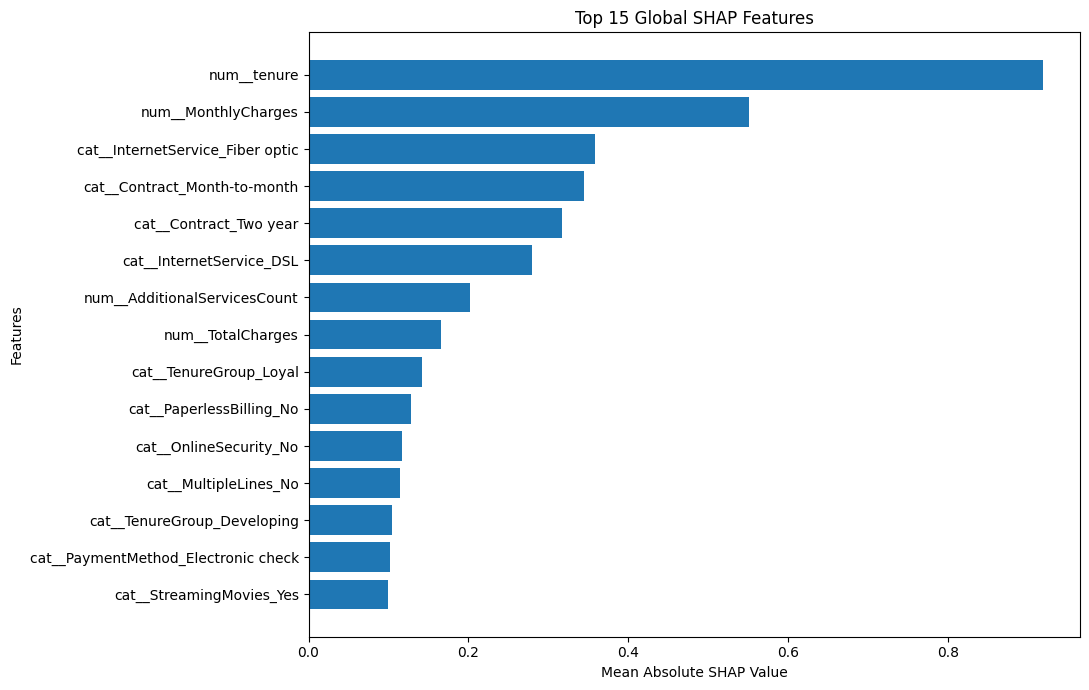


========== SHAP ANALYSIS COMPLETE ==========
Customers explained: 7043
Features explained: 50
SHAP matrix shape: (7043, 50)

Top 15 influential features:


,Feature,Mean_Absolute_SHAP
0,num__tenure,0.919609
1,num__MonthlyCharges,0.550695
2,cat__InternetService_Fiber optic,0.358401
3,cat__Contract_Month-to-month,0.344917
4,cat__Contract_Two year,0.317747
5,cat__InternetService_DSL,0.279350
6,num__AdditionalServicesCount,0.201886
7,num__TotalCharges,0.165954
8,cat__TenureGroup_Loyal,0.142001
9,cat__PaperlessBilling_No,0.128778



Saved:
- data/shap_feature_importance.csv
- models/shap_values.npz
- dashboard/shap_feature_importance.png


In [21]:
# ============================================
# STEP 14: SHAP MODEL EXPLAINABILITY
# ============================================

import os
import numpy as np
import pandas as pd
import shap
import joblib
import matplotlib.pyplot as plt

# 1. Load dataset and trained model
telco = pd.read_csv(
    os.path.join(DATA_PATH, "telco_churn_feature_engineered.csv")
)

model = joblib.load(
    os.path.join(MODEL_PATH, "final_logistic_regression.pkl")
)

# 2. Prepare input features
X = telco.drop(
    columns=["Churn", "customerID"],
    errors="ignore"
)

# 3. Extract pipeline components
preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["model"]

# 4. Transform input data
X_transformed = preprocessor.transform(X)

if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()

feature_names = preprocessor.get_feature_names_out()

# 5. Create SHAP explainer
# Use a representative background sample of 100 customers
background = shap.sample(
    X_transformed,
    100,
    random_state=42
)

explainer = shap.LinearExplainer(
    classifier,
    background
)

# 6. Calculate SHAP values for all customers
shap_values = explainer.shap_values(X_transformed)

# Handle possible multi-class output
if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap_values = np.asarray(shap_values)

# 7. Calculate global feature importance
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# 8. Save SHAP results
shap_importance.to_csv(
    os.path.join(DATA_PATH, "shap_feature_importance.csv"),
    index=False
)

np.savez_compressed(
    os.path.join(MODEL_PATH, "shap_values.npz"),
    shap_values=shap_values,
    feature_names=feature_names
)

# 9. Create global importance plot
top_features = shap_importance.head(15).sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

plt.figure(figsize=(11, 7))
plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.title("Top 15 Global SHAP Features")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig(
    os.path.join(DASHBOARD_PATH, "shap_feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 10. Final report
print("\n========== SHAP ANALYSIS COMPLETE ==========")
print("Customers explained:", len(X))
print("Features explained:", len(feature_names))
print("SHAP matrix shape:", shap_values.shape)

print("\nTop 15 influential features:")
display(shap_importance.head(15))

print("\nSaved:")
print("- data/shap_feature_importance.csv")
print("- models/shap_values.npz")
print("- dashboard/shap_feature_importance.png")

### Verify all recovered files

In [22]:
import os

folders = {
    "DATA": DATA_PATH,
    "MODELS": MODEL_PATH,
    "DASHBOARD": DASHBOARD_PATH,
    "DOCUMENTATION": DOC_PATH
}

for folder_name, folder_path in folders.items():
    print(f"\n{'='*15} {folder_name} {'='*15}")

    files = os.listdir(folder_path)

    if not files:
        print("No files found.")

    for file in sorted(files):
        size = os.path.getsize(
            os.path.join(folder_path, file)
        ) / (1024 * 1024)

        print(f"{file} — {size:.2f} MB")


=============== DATA ===============
clv_predictions.csv — 0.36 MB
cox_hazard_ratios.csv — 0.00 MB
customer_segmentation.csv — 0.62 MB
online_retail_II.xlsx — 43.51 MB
shap_feature_importance.csv — 0.00 MB
telco_churn_feature_engineered.csv — 0.99 MB
telco_churn_processed.csv — 0.93 MB
telco_churn_raw.csv — 0.93 MB

=============== MODELS ===============
bgnbd_model.pkl — 0.18 MB
bgnbd_parameters.json — 0.00 MB
cox_model_parameters.json — 0.00 MB
customer_segmentation_scaler.pkl — 0.00 MB
final_logistic_regression.pkl — 0.01 MB
gamma_gamma_parameters.json — 0.00 MB
kmeans_segmentation_model.pkl — 0.02 MB
shap_values.npz — 0.20 MB

=============== DASHBOARD ===============
shap_feature_importance.png — 0.22 MB

=============== DOCUMENTATION ===============
No files found.


### Inspect Dashboard Data Sources

In [23]:
import pandas as pd
import os

files_to_inspect = {
    "Telco Churn": "telco_churn_feature_engineered.csv",
    "CLV Predictions": "clv_predictions.csv",
    "Customer Segmentation": "customer_segmentation.csv",
    "SHAP Importance": "shap_feature_importance.csv",
    "Survival Analysis": "cox_hazard_ratios.csv"
}

for name, filename in files_to_inspect.items():
    path = os.path.join(DATA_PATH, filename)
    df = pd.read_csv(path)

    print(f"\n{'='*55}")
    print(name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nSample:")
    display(df.head(2))


Telco Churn
Shape: (7043, 23)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TenureGroup', 'AdditionalServicesCount']

Sample:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,AdditionalServicesCount
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New,1
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,Established,2



CLV Predictions
Shape: (4189, 8)
Columns: ['Customer ID', 'frequency', 'recency', 'T', 'monetary_value', 'predicted_purchases_90d', 'predicted_avg_order_value', 'predicted_clv_90d']

Sample:


,Customer ID,frequency,recency,T,monetary_value,predicted_purchases_90d,predicted_avg_order_value,predicted_clv_90d
0,12346,7.0,400.0,725.0,11066.637143,0.618367,11350.087962,7018.517595
1,12347,7.0,402.0,404.0,615.714286,1.461076,631.995121,923.392980



Customer Segmentation
Shape: (5878, 12)
Columns: ['Customer ID', 'FirstPurchase', 'LastPurchase', 'Frequency', 'Monetary', 'TotalQuantity', 'Recency', 'CustomerTenure', 'AverageOrderValue', 'AverageQuantity', 'Cluster', 'Segment']

Sample:


,Customer ID,FirstPurchase,LastPurchase,Frequency,Monetary,TotalQuantity,Recency,CustomerTenure,AverageOrderValue,AverageQuantity,Cluster,Segment
0,12346.0,2009-12-14 08:34:00,2011-01-18 10:01:00,12,77556.46,74285,326,400,6463.038333,6190.416667,2,Champions
1,12347.0,2010-10-31 14:20:00,2011-12-07 15:52:00,8,4921.53,2967,2,402,615.191250,370.875000,2,Champions



SHAP Importance
Shape: (50, 2)
Columns: ['Feature', 'Mean_Absolute_SHAP']

Sample:


,Feature,Mean_Absolute_SHAP
0,num__tenure,0.919609
1,num__MonthlyCharges,0.550695



Survival Analysis
Shape: (10, 12)
Columns: ['covariate', 'coef', 'exp(coef)', 'se(coef)', 'coef lower 95%', 'coef upper 95%', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'cmp to', 'z', 'p', '-log2(p)']

Sample:


,covariate,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
0,MonthlyCharges,-0.004666,0.995345,0.000965,-0.006558,-0.002773,0.993463,0.997230,0.0,-4.832536,0.000001,19.500701
1,SeniorCitizen,0.019031,1.019213,0.048251,-0.075539,0.113601,0.927244,1.120305,0.0,0.394423,0.693269,0.528513


## Build The StreamLit DashBoard

In [24]:
%%writefile /content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence/dashboard/app.py

import os
import json
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px
import plotly.graph_objects as go

from lifelines import KaplanMeierFitter

# =====================================================
# CONFIGURATION
# =====================================================

st.set_page_config(
    page_title="CLV & Churn Intelligence",
    page_icon="📊",
    layout="wide"
)

BASE_DIR = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
DATA_DIR = os.path.join(BASE_DIR, "data")
MODEL_DIR = os.path.join(BASE_DIR, "models")

# =====================================================
# CUSTOM CSS
# =====================================================

st.markdown("""
<style>
    .stApp {
        background-color: #0B1120;
        color: #E5E7EB;
    }

    [data-testid="stMetric"] {
        background-color: #151F32;
        border: 1px solid #26344D;
        padding: 18px;
        border-radius: 12px;
    }

    [data-testid="stMetricValue"] {
        color: #38BDF8;
    }

    h1, h2, h3 {
        color: #F8FAFC;
    }

    .block-container {
        padding-top: 2rem;
    }

    div[data-testid="stTabs"] button {
        font-size: 14px;
    }
</style>
""", unsafe_allow_html=True)

# =====================================================
# LOAD DATA
# =====================================================

@st.cache_data
def load_data():

    telco = pd.read_csv(
        os.path.join(DATA_DIR, "telco_churn_feature_engineered.csv")
    )

    clv = pd.read_csv(
        os.path.join(DATA_DIR, "clv_predictions.csv")
    )

    segmentation = pd.read_csv(
        os.path.join(DATA_DIR, "customer_segmentation.csv")
    )

    shap_data = pd.read_csv(
        os.path.join(DATA_DIR, "shap_feature_importance.csv")
    )

    survival = pd.read_csv(
        os.path.join(DATA_DIR, "cox_hazard_ratios.csv")
    )

    return telco, clv, segmentation, shap_data, survival


@st.cache_resource
def load_models():

    churn_model = joblib.load(
        os.path.join(MODEL_DIR, "final_logistic_regression.pkl")
    )

    kmeans_model = joblib.load(
        os.path.join(MODEL_DIR, "kmeans_segmentation_model.pkl")
    )

    return churn_model, kmeans_model


telco, clv, segmentation, shap_data, survival = load_data()
churn_model, kmeans_model = load_models()

# =====================================================
# CHURN PREDICTIONS
# =====================================================

@st.cache_data
def calculate_churn_scores(data):

    X = data.drop(
        columns=["Churn", "customerID"],
        errors="ignore"
    )

    probabilities = churn_model.predict_proba(X)[:, 1]

    results = data[["customerID", "tenure", "MonthlyCharges",
                    "Contract", "InternetService", "Churn"]].copy()

    results["ChurnProbability"] = probabilities
    results["PredictedChurn"] = (probabilities >= 0.30).astype(int)

    return results


churn_results = calculate_churn_scores(telco)

# =====================================================
# SIDEBAR
# =====================================================

st.sidebar.title("📊 CLV INTELLIGENCE")

st.sidebar.caption("Customer Lifetime Value & Churn Analytics")

st.sidebar.markdown("---")

st.sidebar.markdown("### Navigation")
st.sidebar.markdown("""
- Executive Overview
- Churn Intelligence
- SHAP Explainability
- Survival Analytics
- CLV Analytics
- Customer Segmentation
- Retention ROI Simulator
""")

st.sidebar.markdown("---")
st.sidebar.caption("Portfolio Analytics Project")
st.sidebar.caption("Models: Logistic Regression | BG/NBD | Gamma-Gamma | K-Means | Cox PH")

# =====================================================
# HEADER
# =====================================================

st.title("Customer Lifetime Value & Churn Intelligence")
st.markdown(
    "An integrated analytics platform for customer retention, "
    "churn risk assessment and revenue intelligence."
)

st.markdown("---")

# =====================================================
# TABS
# =====================================================

tabs = st.tabs([
    "Executive Overview",
    "Churn Intelligence",
    "SHAP Explainability",
    "Survival Analytics",
    "CLV Analytics",
    "Customer Segmentation",
    "ROI Simulator"
])

# =====================================================
# 1. EXECUTIVE OVERVIEW
# =====================================================

with tabs[0]:

    st.header("Executive Overview")

    total_customers = len(telco)
    actual_churn = (telco["Churn"] == "Yes").sum()
    churn_rate = actual_churn / total_customers * 100

    predicted_revenue = clv["predicted_clv_90d"].sum()
    average_clv = clv["predicted_clv_90d"].mean()

    repeat_customers = len(clv)

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Telco Customers", f"{total_customers:,}")
    col2.metric("Historical Churn Rate", f"{churn_rate:.2f}%")
    col3.metric("Repeat Retail Customers", f"{repeat_customers:,}")
    col4.metric("Predicted 90-Day Revenue", f"£{predicted_revenue:,.0f}")

    st.markdown("---")

    col1, col2 = st.columns(2)

    with col1:

        st.subheader("Historical Churn Distribution")

        churn_dist = telco["Churn"].value_counts().reset_index()
        churn_dist.columns = ["Churn", "Customers"]

        fig = px.pie(
            churn_dist,
            names="Churn",
            values="Customers",
            hole=0.55,
            title="Customer Churn Composition"
        )

        fig.update_layout(template="plotly_dark")
        st.plotly_chart(fig, use_container_width=True)

    with col2:

        st.subheader("Customer Contract Distribution")

        contract_data = (
            telco.groupby(["Contract", "Churn"])
            .size()
            .reset_index(name="Customers")
        )

        fig = px.bar(
            contract_data,
            x="Contract",
            y="Customers",
            color="Churn",
            barmode="group",
            title="Customers by Contract Type"
        )

        fig.update_layout(template="plotly_dark")
        st.plotly_chart(fig, use_container_width=True)

    st.markdown("---")

    st.subheader("Churn Risk Distribution")

    risk_data = churn_results.copy()

    risk_data["Risk Category"] = pd.cut(
        risk_data["ChurnProbability"],
        bins=[0, 0.30, 0.60, 1.0],
        labels=["Low Risk", "Medium Risk", "High Risk"],
        include_lowest=True
    )

    risk_summary = (
        risk_data["Risk Category"]
        .value_counts()
        .reindex(["Low Risk", "Medium Risk", "High Risk"])
        .reset_index()
    )

    risk_summary.columns = ["Risk Category", "Customers"]

    fig = px.bar(
        risk_summary,
        x="Risk Category",
        y="Customers",
        color="Risk Category",
        title="Model-Based Customer Risk Distribution"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.caption(
        "Churn scores are model predictions using a 0.30 classification threshold. "
        "CLV is estimated future gross revenue for repeat retail customers, not profit."
    )

# =====================================================
# 2. CHURN INTELLIGENCE
# =====================================================

with tabs[1]:

    st.header("Churn Intelligence")

    col1, col2, col3 = st.columns(3)

    predicted_churners = churn_results["PredictedChurn"].sum()

    col1.metric("Customers Screened", f"{len(churn_results):,}")
    col2.metric("Predicted High Risk", f"{predicted_churners:,}")
    col3.metric(
        "Predicted High-Risk Share",
        f"{predicted_churners / len(churn_results) * 100:.1f}%"
    )

    st.markdown("---")

    st.subheader("Churn Probability Distribution")

    fig = px.histogram(
        churn_results,
        x="ChurnProbability",
        nbins=40,
        color="Churn",
        barmode="overlay",
        title="Predicted Churn Probability"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Churn Risk by Contract")

    contract_risk = (
        churn_results.groupby("Contract", observed=False)
        ["ChurnProbability"].mean()
        .reset_index()
    )

    contract_risk["Average Risk (%)"] = (
        contract_risk["ChurnProbability"] * 100
    )

    fig = px.bar(
        contract_risk,
        x="Contract",
        y="Average Risk (%)",
        title="Average Predicted Churn Probability by Contract"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Customer Risk Explorer")

    risk_filter = st.selectbox(
        "Select customer risk category",
        ["All", "High Risk", "Low Risk"]
    )

    filtered = churn_results.copy()

    if risk_filter == "High Risk":
        filtered = filtered[filtered["PredictedChurn"] == 1]

    elif risk_filter == "Low Risk":
        filtered = filtered[filtered["PredictedChurn"] == 0]

    st.dataframe(
        filtered.sort_values(
            "ChurnProbability",
            ascending=False
        ).head(100),
        use_container_width=True
    )

    st.download_button(
        "Download Customer Risk Report",
        data=filtered.to_csv(index=False),
        file_name="customer_churn_risk_report.csv",
        mime="text/csv"
    )

    st.caption(
        "The model is designed for high-recall risk screening. "
        "False positives are possible; predictions should not trigger "
        "automatic customer actions."
    )

# =====================================================
# 3. SHAP EXPLAINABILITY
# =====================================================

with tabs[2]:

    st.header("Model Explainability")

    st.write(
        "Global SHAP importance measures the average magnitude of each "
        "feature's contribution to the model output."
    )

    top_n = st.slider(
        "Number of features",
        min_value=5,
        max_value=30,
        value=15
    )

    top_shap = shap_data.head(top_n).sort_values(
        "Mean_Absolute_SHAP"
    )

    fig = px.bar(
        top_shap,
        x="Mean_Absolute_SHAP",
        y="Feature",
        orientation="h",
        title=f"Top {top_n} Global SHAP Features"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Feature Importance Table")

    st.dataframe(
        shap_data.head(top_n),
        use_container_width=True
    )

    image_path = os.path.join(
        os.path.dirname(__file__),
        "shap_feature_importance.png"
    )

    if os.path.exists(image_path):
        st.image(
            image_path,
            caption="Saved Global SHAP Feature Importance"
        )

    st.info(
        "SHAP explains model behaviour, not causal relationships. "
        "Mean absolute SHAP values show importance magnitude, not direction."
    )

# =====================================================
# 4. SURVIVAL ANALYTICS
# =====================================================

with tabs[3]:

    st.header("Customer Survival Analytics")

    st.write(
        "Kaplan-Meier analysis estimates the proportion of customers "
        "remaining before the recorded churn event over tenure."
    )

    km_data = telco[["tenure", "Churn"]].copy()

    km_data["Event"] = (km_data["Churn"] == "Yes").astype(int)

    kmf = KaplanMeierFitter()

    kmf.fit(
        durations=km_data["tenure"],
        event_observed=km_data["Event"],
        label="All Customers"
    )

    survival_curve = kmf.survival_function_.reset_index()

    fig = go.Figure()

    fig.add_trace(
        go.Scatter(
            x=survival_curve["timeline"],
            y=survival_curve["All Customers"],
            mode="lines",
            name="Customer Survival"
        )
    )

    fig.update_layout(
        title="Kaplan-Meier Customer Survival Curve",
        xaxis_title="Customer Tenure (Months)",
        yaxis_title="Estimated Survival Probability",
        yaxis=dict(tickformat=".0%"),
        template="plotly_dark"
    )

    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Survival by Contract Type")

    fig = go.Figure()

    for contract in telco["Contract"].unique():

        subset = telco[telco["Contract"] == contract]

        km = KaplanMeierFitter()

        km.fit(
            subset["tenure"],
            event_observed=(subset["Churn"] == "Yes"),
            label=contract
        )

        curve = km.survival_function_

        fig.add_trace(
            go.Scatter(
                x=curve.index,
                y=curve.iloc[:, 0],
                mode="lines",
                name=contract
            )
        )

    fig.update_layout(
        title="Survival Probability by Contract",
        xaxis_title="Tenure (Months)",
        yaxis_title="Survival Probability",
        yaxis=dict(tickformat=".0%"),
        template="plotly_dark"
    )

    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Cox Proportional Hazards Results")

    selected = survival[
        ["covariate", "exp(coef)", "p",
         "exp(coef) lower 95%", "exp(coef) upper 95%"]
    ].copy()

    st.dataframe(
        selected.sort_values("exp(coef)", ascending=False),
        use_container_width=True
    )

    st.info(
        "Cox model concordance index during training: 0.8257. "
        "Some proportional-hazards diagnostics were previously flagged. "
        "Hazard ratios should therefore be interpreted cautiously."
    )

    st.caption(
        "This is exploratory survival analysis based on the available "
        "cross-sectional customer tenure and churn status, not a fully "
        "observed customer lifecycle history."
    )

# =====================================================
# 5. CLV ANALYTICS
# =====================================================

with tabs[4]:

    st.header("Customer Lifetime Value Analytics")

    total_clv = clv["predicted_clv_90d"].sum()
    mean_clv = clv["predicted_clv_90d"].mean()
    median_clv = clv["predicted_clv_90d"].median()

    col1, col2, col3 = st.columns(3)

    col1.metric("Predicted 90-Day Revenue", f"£{total_clv:,.0f}")
    col2.metric("Average Predicted CLV", f"£{mean_clv:,.2f}")
    col3.metric("Median Predicted CLV", f"£{median_clv:,.2f}")

    st.markdown("---")

    st.subheader("CLV Distribution")

    fig = px.histogram(
        clv,
        x="predicted_clv_90d",
        nbins=50,
        title="Predicted 90-Day Customer Value"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Top 20 Customers by Predicted CLV")

    top_clv = clv.nlargest(20, "predicted_clv_90d")

    fig = px.bar(
        top_clv,
        x="Customer ID",
        y="predicted_clv_90d",
        title="Highest Predicted Customer Values"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("CLV Customer Explorer")

    st.dataframe(
        clv.sort_values(
            "predicted_clv_90d",
            ascending=False
        ).head(100),
        use_container_width=True
    )

    st.download_button(
        "Download CLV Predictions",
        data=clv.to_csv(index=False),
        file_name="customer_clv_predictions.csv",
        mime="text/csv"
    )

    st.caption(
        "CLV represents estimated 90-day gross revenue for repeat purchasers. "
        "It is not profit, and individual-level forecast accuracy was limited "
        "in historical validation."
    )

# =====================================================
# 6. CUSTOMER SEGMENTATION
# =====================================================

with tabs[5]:

    st.header("Customer Segmentation")

    segment_summary = (
        segmentation.groupby("Segment")
        .agg(
            Customers=("Customer ID", "count"),
            Revenue=("Monetary", "sum"),
            AverageRevenue=("Monetary", "mean"),
            AverageFrequency=("Frequency", "mean"),
            AverageRecency=("Recency", "mean")
        )
        .reset_index()
    )

    segment_summary["Revenue Share (%)"] = (
        segment_summary["Revenue"] /
        segment_summary["Revenue"].sum() * 100
    )

    col1, col2 = st.columns(2)

    with col1:

        fig = px.pie(
            segment_summary,
            names="Segment",
            values="Customers",
            hole=0.5,
            title="Customer Distribution by Segment"
        )

        fig.update_layout(template="plotly_dark")
        st.plotly_chart(fig, use_container_width=True)

    with col2:

        fig = px.bar(
            segment_summary,
            x="Segment",
            y="Revenue",
            color="Segment",
            title="Historical Revenue by Segment"
        )

        fig.update_layout(template="plotly_dark")
        st.plotly_chart(fig, use_container_width=True)

    st.subheader("Segment Performance")

    st.dataframe(
        segment_summary.sort_values(
            "Revenue",
            ascending=False
        ),
        use_container_width=True
    )

    st.subheader("Customer Behaviour")

    fig = px.scatter(
        segmentation,
        x="Frequency",
        y="Monetary",
        color="Segment",
        size="AverageOrderValue",
        hover_data=["Customer ID", "Recency"],
        log_x=True,
        log_y=True,
        title="Customer Frequency vs Monetary Value"
    )

    fig.update_layout(template="plotly_dark")
    st.plotly_chart(fig, use_container_width=True)

    selected_segment = st.selectbox(
        "Explore a customer segment",
        sorted(segmentation["Segment"].unique())
    )

    segment_customers = segmentation[
        segmentation["Segment"] == selected_segment
    ]

    st.dataframe(
        segment_customers.head(100),
        use_container_width=True
    )

    st.download_button(
        "Download Segment Customers",
        data=segment_customers.to_csv(index=False),
        file_name=f"{selected_segment.lower().replace(' ', '_')}.csv",
        mime="text/csv"
    )

    st.caption(
        "K-Means clusters are exploratory behavioural segments, "
        "not verified churn categories."
    )

# =====================================================
# 7. RETENTION ROI SIMULATOR
# =====================================================

with tabs[6]:

    st.header("Retention ROI Simulator")

    st.write(
        "Estimate the potential financial impact of a retention campaign "
        "using customer CLV and user-defined campaign assumptions."
    )

    col1, col2 = st.columns(2)

    with col1:

        target_customers = st.number_input(
            "Customers targeted",
            min_value=1,
            max_value=100000,
            value=500
        )

        retention_rate = st.slider(
            "Expected retention improvement (%)",
            min_value=1,
            max_value=100,
            value=10
        )

    with col2:

        campaign_cost = st.number_input(
            "Campaign cost per targeted customer (£)",
            min_value=0.0,
            value=10.0,
            step=1.0
        )

        value_per_customer = st.number_input(
            "Expected revenue value per retained customer (£)",
            min_value=0.0,
            value=float(median_clv),
            step=10.0
        )

    retained_customers = target_customers * retention_rate / 100

    revenue_saved = retained_customers * value_per_customer

    total_campaign_cost = target_customers * campaign_cost

    net_return = revenue_saved - total_campaign_cost

    roi = (
        (net_return / total_campaign_cost) * 100
        if total_campaign_cost > 0
        else 0
    )

    st.markdown("---")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Expected Retained Customers", f"{retained_customers:,.0f}")
    col2.metric("Estimated Revenue", f"£{revenue_saved:,.2f}")
    col3.metric("Campaign Cost", f"£{total_campaign_cost:,.2f}")
    col4.metric("Estimated ROI", f"{roi:,.1f}%")

    st.subheader("Campaign Financial Summary")

    fig = go.Figure(
        data=[
            go.Bar(
                x=["Estimated Revenue", "Campaign Cost", "Net Return"],
                y=[revenue_saved, total_campaign_cost, net_return]
            )
        ]
    )

    fig.update_layout(
        title="Retention Campaign Scenario",
        yaxis_title="Amount (£)",
        template="plotly_dark"
    )

    st.plotly_chart(fig, use_container_width=True)

    if roi > 0:
        st.success("The scenario produces a positive estimated return.")
    elif total_campaign_cost == 0:
        st.info("Enter a campaign cost to calculate a meaningful ROI.")
    else:
        st.warning("The scenario produces a negative estimated return.")

    st.caption(
        "Illustrative scenario only. Retention improvement, campaign costs "
        "and revenue value are user assumptions. Revenue is not profit, and "
        "the simulator does not establish causal campaign effectiveness."
    )

# =====================================================
# FOOTER
# =====================================================

st.markdown("---")

st.caption(
    "Customer Lifetime Value & Churn Intelligence System | "
    "Exploratory Portfolio Project | "
    "Results are estimates and should not be treated as guaranteed outcomes."
)

Writing /content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence/dashboard/app.py


### Check for Python syntax errors

In [25]:
import py_compile
import os

app_path = os.path.join(DASHBOARD_PATH, "app.py")

try:
    py_compile.compile(app_path, doraise=True)
    print("✅ Dashboard syntax check passed.")
    print(f"File size: {os.path.getsize(app_path) / 1024:.2f} KB")
except py_compile.PyCompileError as e:
    print("❌ Syntax error found:")
    print(e)

✅ Dashboard syntax check passed.
File size: 20.96 KB


### LAunch the dashboard

In [26]:
!streamlit run "/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence/dashboard/app.py" --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &

In [27]:
import time
import requests

time.sleep(5)

try:
    response = requests.get("http://localhost:8501")
    print("✅ Streamlit server is running.")
    print("HTTP Status:", response.status_code)
except Exception as e:
    print("❌ Server did not start.")
    print(e)
    print(open("/content/streamlit.log").read())

✅ Streamlit server is running.
HTTP Status: 200


### Create a Public Dashboard Link

In [28]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸
added 22 packages in 3s
⠸
⠸3 packages are looking for funding
⠸  run `npm fund` for details
⠸npm notice
npm notice New major version of npm available! 10.8.2 -> 12.2.2
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.2
npm notice To update run: npm install -g npm@12.2.2
npm notice
⠸

### Download CloudFlare Tunnel

In [33]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /usr/local/bin/cloudflared

!chmod +x /usr/local/bin/cloudflared

!/usr/local/bin/cloudflared --version

cloudflared version 2026.11.0 (built 2026-11-12-12:17 UTC)


In [35]:
import requests
import subprocess

# Check local Streamlit server
try:
    r = requests.get("http://127.0.0.1:8501", timeout=10)
    print("LOCAL STREAMLIT:", r.status_code)
except Exception as e:
    print("LOCAL STREAMLIT ERROR:", e)

# Check Streamlit process
result = subprocess.run(
    ["pgrep", "-af", "streamlit"],
    capture_output=True,
    text=True
)
print("\nSTREAMLIT PROCESS:")
print(result.stdout or "No Streamlit process found.")

# Display recent application logs
print("\nSTREAMLIT LOGS:")
try:
    with open("/content/streamlit.log", "r") as f:
        print(f.read()[-5000:])
except Exception as e:
    print(e)

LOCAL STREAMLIT ERROR: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x79e1506d2490>: Failed to establish a new connection: [Errno 111] Connection refused'))

STREAMLIT PROCESS:
No Streamlit process found.

STREAMLIT LOGS:
: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.193.18.123:8501

2026-11-17 10:46:20.402 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-17 10:46:20.513 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-17 10:46:20.584 Please replace `use_container_width` with `widt

The Streamlit server has stopped

### Restarting Streamlit

In [36]:
import subprocess
import time
import requests
import os

# Stop any old Streamlit processes
subprocess.run("pkill -f 'streamlit run' || true", shell=True)

time.sleep(2)

# Start Streamlit independently in the background
log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run",
        f"{DASHBOARD_PATH}/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(10)

try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("Streamlit HTTP Status:", response.status_code)
    print("Process ID:", process.pid)
except Exception as e:
    print("Server error:", e)
    print(open("/content/streamlit.log").read()[-4000:])

Streamlit HTTP Status: 200
Process ID: 14023


In [ ]:
!cloudflared tunnel --no-autoupdate --url http://127.0.0.1:8501

2026-11-17T11:08:48Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-17T11:08:48Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-17T11:08:51Z INF +--------------------------------------------------------------------------------------------+
2026-11-17T11:08:51Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-17T11:08:51Z INF |  https://resumes-broken-stakeholders-participate.trycl